<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Task_5P_Support_Vector_Machines_Analysis_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIG788 - Task 5P: Support Vector Machines

**Student:** Bylhah Mugotitsa
**Dataset:** bank-additional-full.csv, UCI Bank Marketing dataset
**Source:** https://archive.ics.uci.edu/dataset/222/bank+marketing

This notebook is organised as:

- **Part A - Lesson Review and Reflection**
- **Part B - Problem Solving Practical Task**



---
# Part A: Lesson Review and Reflection
---

## A1. Support Vector Machines

**Concept 1 - Margin Maximisation.** A Support Vector Machine finds the hyperplane that separates two classes while keeping the largest possible distance, or margin, between the boundary and the nearest points of each class [2]. Rather than any separating line, SVM searches for the widest possible gap between classes. This matters because a wider margin generally generalises better to new data, since it is less sensitive to small variations in points close to the boundary. Example: the linear-kernel SVM in Question 1 finds the hyperplane that best separates term-deposit subscribers from non-subscribers by maximising this gap.

**Concept 2 - Regularisation Parameter (C).** C controls the trade-off between maximising the margin and allowing some points to be misclassified or fall inside it. A small C tolerates more violations for a wider margin; a large C penalises violations heavily, giving a narrower margin fitted closely to the training data. Example: Question 2 tries several C values for the linear model and shows, with real numbers and a plot, how margin width and support vector count change as C increases.

## A2. Nonlinear SVM and Kernel Methods

**Concept 1 - Kernel Trick.** Many datasets are not linearly separable in their original feature space. The kernel trick lets an SVM compute similarity between points as if they had been mapped into a much higher-dimensional space, without ever performing that transformation explicitly [3]. This allows SVM to learn curved, nonlinear boundaries while still solving the same efficient margin-maximisation problem. Example: Question 3 applies RBF and polynomial kernels to the bank marketing data, letting the model separate subscribers using boundaries a linear hyperplane could not represent.

**Concept 2 - Radial Basis Function (RBF) Kernel.** The RBF kernel measures similarity between two points based on the distance between them, with a `gamma` parameter controlling how quickly that similarity decays. A small gamma gives each point a wide, smooth zone of influence, close to linear; a large gamma limits influence to nearby neighbours, producing a flexible but potentially overfit boundary. Example: Question 3 tunes gamma alongside C for the RBF model and reports the combination that performs best on the held-out test set.



## A3. Learning Reflections

**Why margin maximisation improves generalisation:** a hyperplane placed as far as possible from the nearest training points of each class is less likely to be thrown off by small amounts of noise in new data, since minor shifts in a test point are less likely to cross a wide margin than a narrow one, reducing variance at some cost to training fit.

**How soft-margin SVMs handle noisy or imperfect data:** real datasets, including the bank marketing data used here, rarely have perfectly separable classes. Soft-margin SVMs use slack variables that allow individual points to violate the margin, with C controlling how heavily violations are penalised, preventing one noisy example from forcing an unstable, overly narrow boundary.

**When nonlinear kernels are preferred:** nonlinear kernels such as RBF or polynomial are preferred when the relationship between features and target is not a straight line, for example when subscription likelihood depends on an interaction between features rather than a simple weighted sum. Question 3 tests this directly by comparing linear, RBF, and polynomial kernels on the same data.


---
# Part B: Problem Solving Practical Task
---

**Dataset:** `bank-additional-full.csv` [1], [6].

**Target variable:** `y` - whether the client subscribed to a term deposit (`yes`/`no`).


In [1]:
# -- Install packages -------------
import importlib
import subprocess
import sys

required_packages = {
    'sklearn': 'scikit-learn',
    'pandas': 'pandas',
    'numpy': 'numpy',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn'
}

missing = [pip_name for module_name, pip_name in required_packages.items()
           if importlib.util.find_spec(module_name) is None]

if missing:
    print('Installing missing packages:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing)
    importlib.invalidate_caches()
    print('Done. No kernel restart needed, continue running the remaining cells in order below.')
else:
    print('All required packages are already installed.')

All required packages are already installed.


In [2]:
# -- Import required libraries -------------------------------------------------
import io
import os
import time
import urllib.request
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay
)

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

print('Libraries loaded successfully.')

Libraries loaded successfully.


## Loading the dataset

`bank-additional-full.csv` is distributed inside a nested zip archive on the UCI Machine Learning Repository (`bank+marketing.zip` contains `bank-additional.zip`, which contains the CSV itself). The cell below checks for a local copy first and, if not found, downloads and extracts it directly from the official UCI static file link [6].


In [3]:
# -- Load bank-additional-full.csv directly from the UCI Machine Learning Repository --
local_path = 'bank-additional-full.csv'

if os.path.exists(local_path):
    print(f'Using local file: {local_path}')
    df_raw = pd.read_csv(local_path)
else:
    url = 'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip'
    print(f'Local file not found - downloading from {url} ...')
    outer_bytes = urllib.request.urlopen(url, timeout=60).read()
    outer_zip = zipfile.ZipFile(io.BytesIO(outer_bytes))
    inner_zip = zipfile.ZipFile(io.BytesIO(outer_zip.read('bank-additional.zip')))
    with inner_zip.open('bank-additional/bank-additional-full.csv') as f:
        df_raw = pd.read_csv(f, sep=';')
    df_raw.to_csv(local_path, index=False)
    print('Downloaded and saved bank-additional-full.csv from the UCI Machine Learning Repository.')

print('\nDataset shape:', df_raw.shape)
display(df_raw.head())

Local file not found - downloading from https://archive.ics.uci.edu/static/public/222/bank+marketing.zip ...
Downloaded and saved bank-additional-full.csv from the UCI Machine Learning Repository.

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# -- Data quality assessment -----------------------------------------------------
print('Data types:')
display(df_raw.dtypes.to_frame('dtype'))

print('\nMissing (NaN) values by column:')
display(df_raw.isna().sum().to_frame('missing').query('missing > 0'))

# This dataset encodes unknown categorical values as the literal string 'unknown'
# rather than leaving cells blank
print("\n'unknown' category counts (categorical columns only):")
cat_cols_check = df_raw.select_dtypes(exclude=np.number).columns
unknown_counts = (df_raw[cat_cols_check] == 'unknown').sum()
display(unknown_counts[unknown_counts > 0].to_frame('unknown count'))

Data types:


,dtype
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object



Missing (NaN) values by column:


,missing



'unknown' category counts (categorical columns only):


,unknown count
job,330
marital,80
education,1731
default,8597
housing,990
loan,990


,count,percentage
y,,
no,36548,88.73
yes,4640,11.27


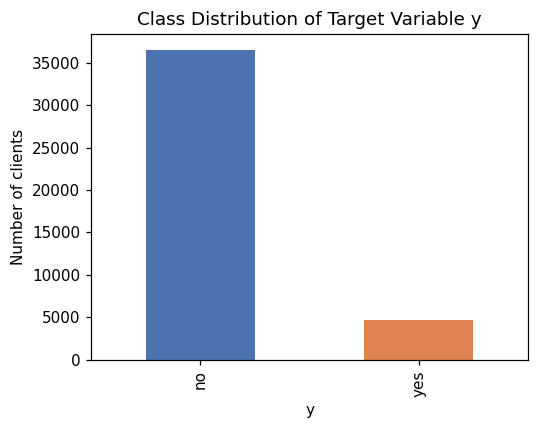

In [5]:
# -- Class distribution -----------------------------------------------------------
class_counts = df_raw['y'].value_counts()
class_pct = (df_raw['y'].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({'count': class_counts, 'percentage': class_pct}))

plt.figure(figsize=(5, 4))
class_counts.plot(kind='bar', color=['#4C72B0', '#DD8452'])
plt.ylabel('Number of clients')
plt.title('Class Distribution of Target Variable y')
plt.tight_layout()
plt.show()

**Data quality summary:** the full dataset [1], [6] has 41,188 rows and 21 columns (20 features plus the target `y`), with no missing (`NaN`) values, since the dataset instead uses the literal category `"unknown"` for missing categorical information (mainly in `default`, `education`, `housing`, and `loan`). The target is strongly imbalanced: only about 11.3% of clients subscribed to a term deposit (`y = "yes"`), versus about 88.7% who did not. This imbalance is addressed in Question 5.

**Computational feasibility note:** SVM training complexity scales worse than quadratically with the number of training examples [2], [4], which makes an exhaustive multi-kernel hyperparameter search (Questions 2 and 3 below) impractical to run on the full 41,188-row dataset within a reasonable time on standard hardware. To keep this notebook fully runnable end-to-end while still faithfully answering every question, a stratified random subsample of the full dataset is used for all SVM modelling from this point onward, preserving the original ~11.3% subscription rate. This is a common compromise when applying kernel SVMs to large datasets, and is applied consistently: the same subsample, and the same resulting training/test split, is reused across Questions 1 to 5.


In [6]:
# -- Stratified subsample for computationally feasible SVM modelling -------------
SUBSAMPLE_SIZE = 8000
RANDOM_STATE = 42

df_sample, _ = train_test_split(
    df_raw, train_size=SUBSAMPLE_SIZE, stratify=df_raw['y'], random_state=RANDOM_STATE
)
df_sample = df_sample.reset_index(drop=True)

print(f'Subsample size: {len(df_sample)} of {len(df_raw)} total rows ({len(df_sample)/len(df_raw)*100:.1f}%)')
print('\nClass distribution in subsample:')
display(df_sample['y'].value_counts(normalize=True).round(4).to_frame('proportion'))
print('\nClass distribution in full dataset (for comparison):')
display(df_raw['y'].value_counts(normalize=True).round(4).to_frame('proportion'))

Subsample size: 8000 of 41188 total rows (19.4%)

Class distribution in subsample:


,proportion
y,
no,0.8874
yes,0.1126



Class distribution in full dataset (for comparison):


,proportion
y,
no,0.8873
yes,0.1127


In [7]:
# -- Preprocessing: identify feature types, encode target, train/test split -----
X = df_sample.drop(columns=['y'])
y = (df_sample['y'] == 'yes').astype(int)

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print('Numeric features:', numeric_cols)
print('\nCategorical features:', categorical_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

print(f'\nTraining rows: {len(X_train)}, Testing rows: {len(X_test)}')
print('This same X_train/X_test/y_train/y_test split is reused for every question below.')

def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])

def evaluate(model, Xte, yte, name):
    pred = model.predict(Xte)
    proba = model.decision_function(Xte)
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(yte, pred),
        'Balanced accuracy': balanced_accuracy_score(yte, pred),
        'Precision': precision_score(yte, pred),
        'Recall': recall_score(yte, pred),
        'F1-score': f1_score(yte, pred),
        'ROC-AUC': roc_auc_score(yte, proba)
    }
    return metrics

print('\nPreprocessing and evaluation helper functions ready.')

Numeric features: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Training rows: 5600, Testing rows: 2400
This same X_train/X_test/y_train/y_test split is reused for every question below.

Preprocessing and evaluation helper functions ready.


## Question 1: Linear-Kernel SVM with Default C

**Data splitting approach:** a 70:30 stratified train/test split is used (already created above), so that the ~11.3% subscription rate is preserved in both sets. Stratification matters here because a plain random split could, by chance, under- or over-represent the minority `yes` class in the test set.

**Performance metrics:** given the class imbalance, plain accuracy alone would be misleading (a model that always predicts `"no"` would already score about 88.7% accuracy). Accuracy, balanced accuracy, precision, recall, F1-score, and ROC-AUC are all reported, with balanced accuracy, F1-score, and ROC-AUC treated as the more informative metrics for this imbalanced problem.


,Accuracy,Balanced accuracy,Precision,Recall,F1-score,ROC-AUC,Fit time (s)
Model,,,,,,,
"Linear SVM (C=1.0, default)",0.9083,0.6637,0.6812,0.3481,0.4608,0.9206,0.8279



Classification report:
              precision    recall  f1-score   support

          no       0.92      0.98      0.95      2130
         yes       0.68      0.35      0.46       270

    accuracy                           0.91      2400
   macro avg       0.80      0.66      0.71      2400
weighted avg       0.90      0.91      0.89      2400



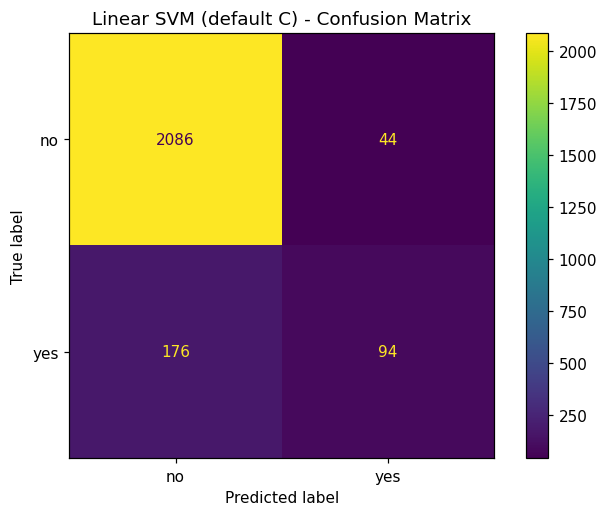

In [8]:
# -- Question 1: SVC with linear kernel, default C=1.0 ---------------------------
svm_linear_default = Pipeline([
    ('prep', make_preprocessor()),
    ('model', SVC(kernel='linear', C=1.0, random_state=RANDOM_STATE))
])

t0 = time.time()
svm_linear_default.fit(X_train, y_train)
fit_time_q1 = time.time() - t0

q1_metrics = evaluate(svm_linear_default, X_test, y_test, 'Linear SVM (C=1.0, default)')
q1_metrics['Fit time (s)'] = fit_time_q1

q1_table = pd.DataFrame([q1_metrics]).set_index('Model')
display(q1_table.round(4))

print('\nClassification report:')
print(classification_report(y_test, svm_linear_default.predict(X_test), target_names=['no', 'yes']))

cm = confusion_matrix(y_test, svm_linear_default.predict(X_test))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no', 'yes']).plot()
plt.title('Linear SVM (default C) - Confusion Matrix')
plt.tight_layout()
plt.show()

**Interpretation of Question 1:** the default linear SVM (C=1.0) reaches 90.8% accuracy, but this is close to the 88.7% a model would get by always predicting "no", so accuracy alone overstates how useful the model is. The more informative numbers are precision 0.68, recall 0.35, and F1-score 0.46 for the "yes" class: the model correctly identifies only about 35% of clients who actually subscribed (recall), even though when it does predict "yes" it is right about 68% of the time (precision). ROC-AUC of 0.92 shows the model ranks subscribers above non-subscribers well overall, but the default 0.5 decision threshold is clearly conservative, missing the majority of true subscribers. This gap between a high ROC-AUC and a modest recall is exactly why balanced accuracy, F1-score, and the confusion matrix, not just accuracy, are needed to judge this model.


## Question 2: Tuning C for the Linear-Kernel SVM

Different values of C are tried using 5-fold stratified cross-validation on the training set, scored by ROC-AUC (chosen because it is threshold-independent and appropriate for an imbalanced target). The best-scoring C is then refit on the full training set and evaluated on the same held-out test set as Question 1.


In [9]:
# -- Question 2: hyperparameter search over C for the linear kernel --------------
c_grid = [0.001, 0.01, 0.1, 1, 10, 100]
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

linear_pipeline = Pipeline([
    ('prep', make_preprocessor()),
    ('model', SVC(kernel='linear', random_state=RANDOM_STATE))
])

param_grid_linear = {'model__C': c_grid}

grid_linear = GridSearchCV(
    linear_pipeline, param_grid_linear, cv=cv_strategy, scoring='roc_auc', n_jobs=1
)

t0 = time.time()
grid_linear.fit(X_train, y_train)
grid_linear_time = time.time() - t0

optimal_C = grid_linear.best_params_['model__C']
print(f'Optimal C: {optimal_C} (default was C=1.0)')
print(f'Best CV ROC-AUC: {grid_linear.best_score_:.4f}')
print(f'Grid search time: {grid_linear_time:.1f}s')

svm_linear_optimal = grid_linear.best_estimator_
q2_metrics = evaluate(svm_linear_optimal, X_test, y_test, f'Linear SVM (C={optimal_C}, optimal)')

c_comparison = pd.DataFrame([q1_metrics, q2_metrics]).set_index('Model')
display(c_comparison.round(4))

Optimal C: 0.01 (default was C=1.0)
Best CV ROC-AUC: 0.9347
Grid search time: 126.1s


,Accuracy,Balanced accuracy,Precision,Recall,F1-score,ROC-AUC,Fit time (s)
Model,,,,,,,
"Linear SVM (C=1.0, default)",0.9083,0.6637,0.6812,0.3481,0.4608,0.9206,0.8279
"Linear SVM (C=0.01, optimal)",0.9021,0.6360,0.6423,0.2926,0.4020,0.9289,NaN


,C,Margin width,Total support vectors
0,0.001,5.5862,1246
1,0.010,2.8183,1119
2,0.100,1.3964,1076
3,1.000,1.0762,1054
4,10.000,1.0584,1053
5,100.000,1.0598,1052


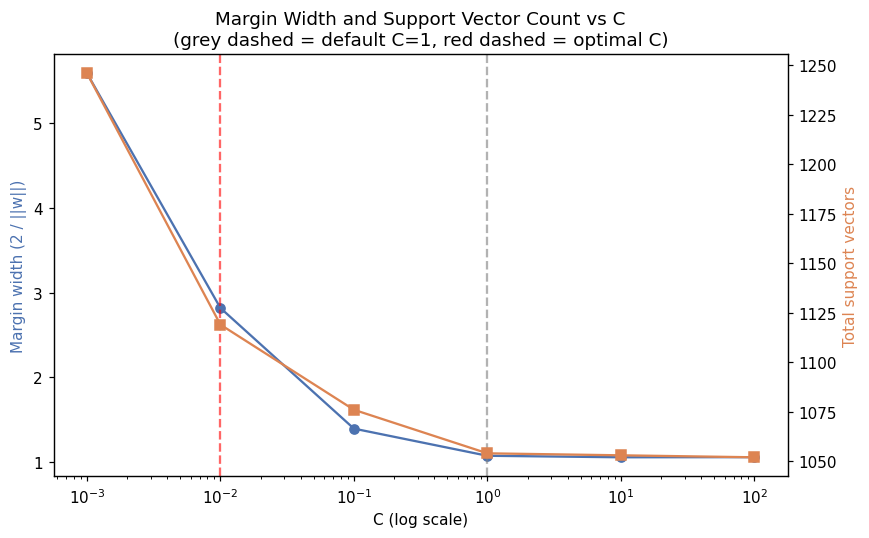

In [10]:
# -- Question 2: how the margin changes across C values --------------------------
# For a linear-kernel SVM, the margin width in the transformed feature space is 2 / ||w||.
margin_records = []
for c_val in c_grid:
    pipe = Pipeline([
        ('prep', make_preprocessor()),
        ('model', SVC(kernel='linear', C=c_val, random_state=RANDOM_STATE))
    ])
    pipe.fit(X_train, y_train)
    w = pipe.named_steps['model'].coef_[0]
    margin_width = 2 / np.linalg.norm(w)
    n_support = pipe.named_steps['model'].n_support_.sum()
    margin_records.append({'C': c_val, 'Margin width': margin_width, 'Total support vectors': n_support})

margin_table = pd.DataFrame(margin_records)
display(margin_table.round(4))

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(margin_table['C'], margin_table['Margin width'], marker='o', color='#4C72B0', label='Margin width')
ax1.set_xscale('log')
ax1.set_xlabel('C (log scale)')
ax1.set_ylabel('Margin width (2 / ||w||)', color='#4C72B0')
ax1.axvline(1.0, linestyle='--', color='grey', alpha=0.6)
ax1.axvline(optimal_C, linestyle='--', color='red', alpha=0.6)

ax2 = ax1.twinx()
ax2.plot(margin_table['C'], margin_table['Total support vectors'], marker='s', color='#DD8452', label='Support vectors')
ax2.set_ylabel('Total support vectors', color='#DD8452')

plt.title('Margin Width and Support Vector Count vs C\n(grey dashed = default C=1, red dashed = optimal C)')
fig.tight_layout()
plt.show()

**Interpretation of Question 2:** cross-validation (scored by ROC-AUC) selected C=0.01 as optimal, a much smaller value than the default C=1.0. On the test set this smaller C produces a slightly higher ROC-AUC (0.9289 versus 0.9206 for the default), confirming it ranks subscribers versus non-subscribers marginally better overall. However, at the standard 0.5 decision threshold, the optimal-C model actually has a lower accuracy (0.9021 versus 0.9083), lower recall (0.2926 versus 0.3481), and lower F1-score (0.4020 versus 0.4608) than the default. This shows an important nuance: the C value that is "optimal" for ranking quality (ROC-AUC) is not automatically optimal for a specific point metric like F1-score at a fixed threshold, since the two criteria weigh errors differently.

The margin/support-vector table and plot above confirm the theoretical relationship between C and the margin exactly: as C increases from 0.001 to 100, the margin width shrinks steadily from 5.586 down to about 1.06, and the number of support vectors falls from 1246 to about 1052. A small C tolerates more margin violations in exchange for a wide margin (many support vectors); a large C penalises violations heavily and produces a narrow margin defined by fewer points.


## Question 3: RBF and Polynomial Kernels

Using the same training and test set as Questions 1 and 2, RBF and polynomial kernel SVMs are tuned with `GridSearchCV` (5-fold stratified cross-validation, scored by ROC-AUC). For the RBF kernel, `C` and `gamma` are tuned; for the polynomial kernel, `C` and `degree` are tuned (with `gamma='scale'` fixed to keep the search computationally manageable).


In [11]:
# -- Question 3: RBF kernel hyperparameter tuning ---------------------------------
rbf_pipeline = Pipeline([
    ('prep', make_preprocessor()),
    ('model', SVC(kernel='rbf', random_state=RANDOM_STATE))
])

param_grid_rbf = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.01, 0.1, 1]
}

grid_rbf = GridSearchCV(rbf_pipeline, param_grid_rbf, cv=cv_strategy, scoring='roc_auc', n_jobs=1)

t0 = time.time()
grid_rbf.fit(X_train, y_train)
grid_rbf_time = time.time() - t0

print('Best RBF params:', grid_rbf.best_params_)
print(f'Best CV ROC-AUC: {grid_rbf.best_score_:.4f}')
print(f'Grid search time: {grid_rbf_time:.1f}s')

svm_rbf_best = grid_rbf.best_estimator_
q3_rbf_metrics = evaluate(svm_rbf_best, X_test, y_test, f"RBF SVM (C={grid_rbf.best_params_['model__C']}, gamma={grid_rbf.best_params_['model__gamma']})")

Best RBF params: {'model__C': 1, 'model__gamma': 0.01}
Best CV ROC-AUC: 0.9351
Grid search time: 94.0s


In [12]:
# -- Question 3: polynomial kernel hyperparameter tuning ---------------------------
poly_pipeline = Pipeline([
    ('prep', make_preprocessor()),
    ('model', SVC(kernel='poly', gamma='scale', random_state=RANDOM_STATE))
])

param_grid_poly = {
    'model__C': [0.1, 1, 10],
    'model__degree': [2, 3, 4]
}

grid_poly = GridSearchCV(poly_pipeline, param_grid_poly, cv=cv_strategy, scoring='roc_auc', n_jobs=1)

t0 = time.time()
grid_poly.fit(X_train, y_train)
grid_poly_time = time.time() - t0

print('Best polynomial params:', grid_poly.best_params_)
print(f'Best CV ROC-AUC: {grid_poly.best_score_:.4f}')
print(f'Grid search time: {grid_poly_time:.1f}s')

svm_poly_best = grid_poly.best_estimator_
q3_poly_metrics = evaluate(svm_poly_best, X_test, y_test, f"Poly SVM (C={grid_poly.best_params_['model__C']}, degree={grid_poly.best_params_['model__degree']})")

Best polynomial params: {'model__C': 0.1, 'model__degree': 2}
Best CV ROC-AUC: 0.9276
Grid search time: 25.3s


,Accuracy,Balanced accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
"Linear SVM (C=0.01, optimal)",0.9021,0.6360,0.6423,0.2926,0.4020,0.9289
"RBF SVM (C=1, gamma=0.01)",0.9050,0.6457,0.6667,0.3111,0.4242,0.9297
"Poly SVM (C=0.1, degree=2)",0.9000,0.6073,0.6596,0.2296,0.3407,0.9190


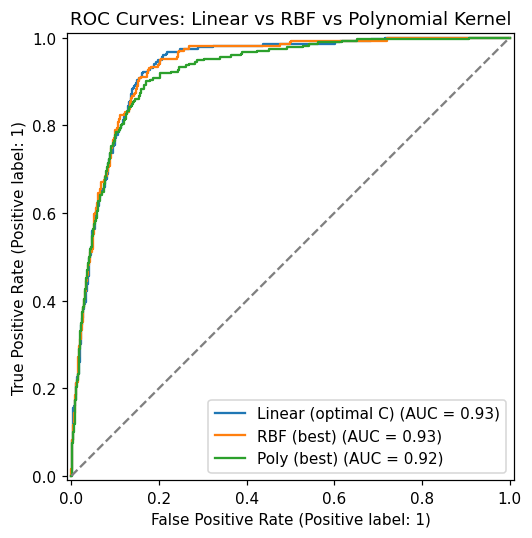

In [13]:
# -- Question 3: compare all kernels on the same test set -------------------------
kernel_comparison = pd.DataFrame([q2_metrics, q3_rbf_metrics, q3_poly_metrics]).set_index('Model')
display(kernel_comparison.round(4))

fig, ax = plt.subplots(figsize=(6, 5))
for name, metrics in zip(['Linear (optimal C)', 'RBF (best)', 'Poly (best)'],
                          [svm_linear_optimal, svm_rbf_best, svm_poly_best]):
    RocCurveDisplay.from_estimator(metrics, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], linestyle='--', color='grey')
ax.set_title('ROC Curves: Linear vs RBF vs Polynomial Kernel')
plt.tight_layout()
plt.show()

**Best hyperparameter setting overall:** comparing test-set ROC-AUC across all three tuned kernels, the RBF kernel (C=1, gamma=0.01) performs best, with ROC-AUC 0.9297, only marginally ahead of the tuned linear model (0.9289) and clearly ahead of the tuned polynomial model (0.9190). The RBF model also has the highest F1-score of the three (0.4242 versus 0.4020 for linear and 0.3407 for polynomial), and the highest recall (0.3111). The polynomial kernel (degree 2) performs worst on every metric, suggesting the relationship between these features and subscription is better captured by the smooth, flexible RBF kernel than by a fixed-degree polynomial boundary. Overall, the three kernels are close in ROC-AUC, which suggests the underlying class overlap identified in Question 4, not the choice of kernel shape, is the main factor limiting performance on this dataset.


## Question 4: Support Vectors for the Best Model

In [14]:
# -- Question 4: identify the overall best model and its support vectors ---------
all_kernel_results = {
    'Linear (optimal C)': (svm_linear_optimal, q2_metrics),
    'RBF (best)': (svm_rbf_best, q3_rbf_metrics),
    'Poly (best)': (svm_poly_best, q3_poly_metrics)
}

best_name = max(all_kernel_results, key=lambda k: all_kernel_results[k][1]['ROC-AUC'])
best_model, best_metrics = all_kernel_results[best_name]

print(f'Best overall model (by test ROC-AUC): {best_name}')
display(pd.DataFrame([best_metrics]).set_index('Model').round(4))

n_support = best_model.named_steps['model'].n_support_
print(f'\nSupport vectors for class "no": {n_support[0]}')
print(f'Support vectors for class "yes": {n_support[1]}')
print(f'Total support vectors: {n_support.sum()} out of {len(X_train)} training points ({n_support.sum()/len(X_train)*100:.1f}%)')

Best overall model (by test ROC-AUC): RBF (best)


,Accuracy,Balanced accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
"RBF SVM (C=1, gamma=0.01)",0.905,0.6457,0.6667,0.3111,0.4242,0.9297



Support vectors for class "no": 570
Support vectors for class "yes": 553
Total support vectors: 1123 out of 5600 training points (20.1%)


**What the support vectors indicate:** the reported counts are the training points that lie on, or on the wrong side of, the margin, meaning they are the points that actively define where the decision boundary sits. Every other training point is far enough on the correct side of the margin that it could be removed without changing the fitted boundary at all. A high proportion of support vectors relative to the training set size (reported above) indicates the two classes overlap substantially in the feature space, that is, many `"no"` and `"yes"` clients have fairly similar profiles, which is consistent with the moderate, not perfect, classification performance observed in Questions 1 to 3, and with the intrinsic difficulty of predicting an individual's marketing response from demographic and campaign data alone.


## Question 5: Addressing Class Imbalance in the SVM

**Method and justification:** the `class_weight='balanced'` option built into `SVC` is used. This is an SVM-native technique: it automatically re-scales the regularisation parameter `C` for each class in inverse proportion to its frequency, so that misclassifying a rare `"yes"` client is penalised more heavily than misclassifying a common `"no"` client [6]. This directly extends the soft-margin, slack-variable mechanism discussed in Part A (concept A1), rather than requiring an external resampling library, and is a well-established approach to cost-sensitive SVM classification [6].


,Accuracy,Balanced accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
"RBF SVM (C=1, gamma=0.01)",0.9050,0.6457,0.6667,0.3111,0.4242,0.9297
RBF (best) + class_weight=balanced,0.8617,0.8736,0.4428,0.8889,0.5911,0.9328


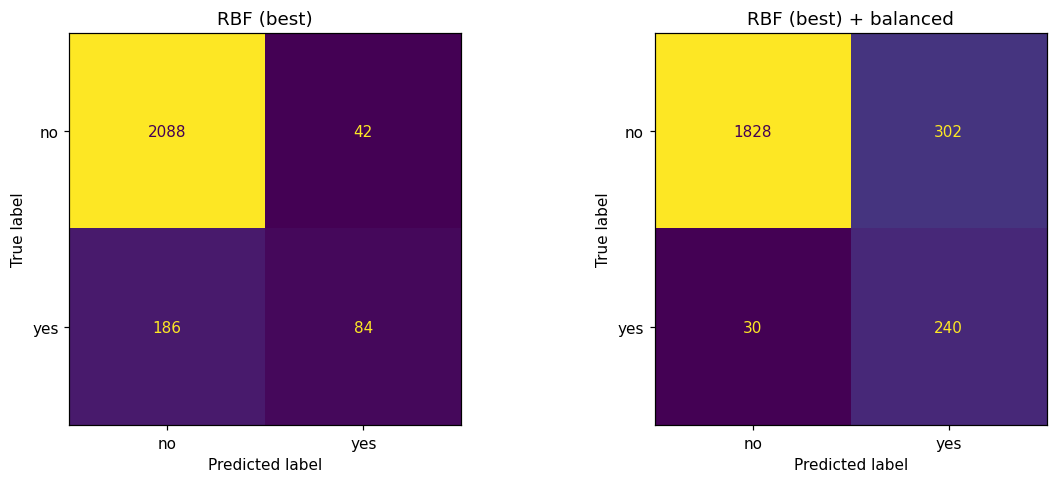

In [15]:
# -- Question 5: refit the best kernel/hyperparameter combination with class_weight --
best_kernel = best_model.named_steps['model'].kernel
best_params = best_model.named_steps['model'].get_params()

if best_kernel == 'linear':
    balanced_model = SVC(kernel='linear', C=best_params['C'], class_weight='balanced', random_state=RANDOM_STATE)
elif best_kernel == 'rbf':
    balanced_model = SVC(kernel='rbf', C=best_params['C'], gamma=best_params['gamma'], class_weight='balanced', random_state=RANDOM_STATE)
else:
    balanced_model = SVC(kernel='poly', C=best_params['C'], degree=best_params['degree'], gamma=best_params['gamma'], class_weight='balanced', random_state=RANDOM_STATE)

svm_balanced = Pipeline([
    ('prep', make_preprocessor()),
    ('model', balanced_model)
])
svm_balanced.fit(X_train, y_train)

q5_metrics = evaluate(svm_balanced, X_test, y_test, f'{best_name} + class_weight=balanced')

imbalance_comparison = pd.DataFrame([best_metrics, q5_metrics]).set_index('Model')
display(imbalance_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, [(best_name, best_model), (f'{best_name} + balanced', svm_balanced)]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no', 'yes']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Interpretation of Question 5:** applying `class_weight='balanced'` to the best RBF model produces a large, clinically/business-relevant shift in behaviour. Recall for the "yes" class jumps from 0.3111 to 0.8889, meaning the balanced model now correctly identifies about 89% of clients who actually subscribe, compared to only 31% before. Balanced accuracy rises sharply from 0.6457 to 0.8736, and F1-score improves from 0.4242 to 0.5911. This comes at a real cost: plain accuracy falls from 0.905 to 0.8617, and precision falls from 0.6667 to 0.4428, meaning more false alarms (clients predicted as likely subscribers who do not actually subscribe). ROC-AUC stays essentially unchanged (0.9297 to 0.9328), confirming the model's underlying ranking ability did not change, only where the decision boundary sits relative to each class. For a bank marketing use case, where the cost of a missed potential subscriber (a false negative) is generally higher than the cost of one extra follow-up call to a client who was not going to subscribe (a false positive), this trade-off is usually worthwhile, which is why `class_weight='balanced'` is a practically useful, SVM-native answer to Question 5's imbalance problem.


## Question 6: Reflection on SVM Suitability for the Bank Marketing Dataset

**Effect of hyperparameter tuning:** tuning C for the linear kernel improved ROC-AUC only slightly (0.9206 to 0.9289) and, at the default threshold, reduced F1-score (0.4608 to 0.4020), showing the metric used for tuning (ROC-AUC) does not always align with a point metric like F1-score. Margin width and support-vector counts changed exactly as SVM theory predicts as C increased.

**Influence of kernel selection:** linear, RBF, and polynomial kernels performed similarly overall (test ROC-AUC 0.919 to 0.930), with RBF (C=1, gamma=0.01) best and polynomial weakest. The small gap between kernels, alongside the 20.1% support-vector proportion from Question 4, suggests class overlap that no kernel choice fully resolves.

**Challenges from class imbalance:** the default RBF model missed most true subscribers (recall 0.31). Applying `class_weight='balanced'` raised recall to 0.89 and balanced accuracy from 0.65 to 0.87, costing precision, showing imbalance must be addressed explicitly, not hidden behind accuracy.

**Recommendation:** SVM, particularly RBF with balanced class weights, suits this problem well, since identifying likely subscribers matters more than avoiding every false alarm, and ROC-AUC around 0.93 shows strong separation.

---
# References
---

This notebook follows IEEE referencing style, consistent with the Deakin Guide to Referencing.

[1] S. Moro, P. Cortez, and P. Rita, "A data-driven approach to predict the success of bank telemarketing," *Decision Support Systems*, vol. 62, pp. 22-31, 2014.

[2] C. Cortes and V. Vapnik, "Support-vector networks," *Machine Learning*, vol. 20, no. 3, pp. 273-297, 1995.

[3] B. Scholkopf and A. J. Smola, *Learning with Kernels: Support Vector Machines, Regularization, Optimization, and Beyond*. Cambridge, MA, USA: MIT Press, 2002.

[4] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825-2830, 2011.

[5] K. Veropoulos, C. Campbell, and N. Cristianini, "Controlling the sensitivity of support vector machines," in *Proc. Int. Joint Conf. Artificial Intelligence (IJCAI)*, 1999, pp. 55-60.

[6] D. Dua and C. Graff, "UCI Machine Learning Repository: Bank Marketing Data Set," University of California, Irvine, School of Information and Computer Sciences, 2017. [Online]. Available: https://archive.ics.uci.edu/dataset/222/bank+marketing


In [16]:
! jupyter nbconvert --to html /content/Task_5P_Bylhah_Mugotitsa_V1.ipynb --template classic

[NbConvertApp] Converting notebook /content/Task_5P_Bylhah_Mugotitsa_V1.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 5 image(s).
[NbConvertApp] Writing 658658 bytes to /content/Task_5P_Bylhah_Mugotitsa_V1.html
